<a href="https://colab.research.google.com/github/harshajangle/CSL701_CE12_Machine_Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Harsha Tukaram Jangle

Batch : CE01


Roll Number : CE12



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import urllib.request
import os

# URL of the dataset
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
csv_path = "Mall_Customers.csv"

# Download the file if it doesn't exist locally
if not os.path.exists(csv_path):
    print("Downloading Mall_Customers.csv...")
    urllib.request.urlretrieve(url, csv_path)

# Load the dataset
df = pd.read_csv(csv_path)

# Display basic information and the first 5 rows
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
import pandas as pd
# Task 1: Check dataset statistics, null values, and structure
print("Dataset Description:")
display(df.describe())

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset Description:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000,2.720000
std,57.879185,13.969007,26.264721,25.823522,1.748395
min,1.000000,18.000000,15.000000,1.000000,-1.000000
25%,50.750000,28.750000,41.500000,34.750000,2.000000
50%,100.500000,36.000000,61.500000,50.000000,3.000000
75%,150.250000,49.000000,78.000000,73.000000,4.000000
max,200.000000,70.000000,137.000000,99.000000,6.000000



Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
Cluster                   0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:
# Task 2: Feature Selection and Standardization
# Selecting Annual Income (k$) and Spending Score (1-100)
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

# Initializing and applying StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape of scaled features:", X_scaled.shape)
print("First 5 scaled rows:\n", X_scaled[:5])

Shape of scaled features: (200, 2)
First 5 scaled rows:
 [[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


In [ ]:
import pandas as pd
# Task 2: Verify the distribution of scaled features
scaled_df = pd.DataFrame(X_scaled, columns=features)
print("Mean of scaled features (Should be approx 0):")
print(scaled_df.mean())
print("\nStandard Deviation of scaled features (Should be approx 1):")
print(scaled_df.std())

Mean of scaled features (Should be approx 0):
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard Deviation of scaled features (Should be approx 1):
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

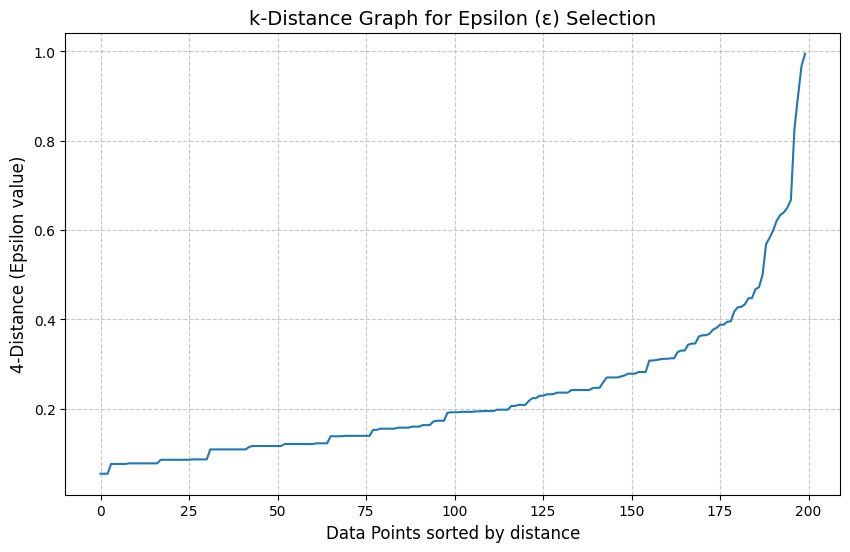

In [ ]:
# Task 3: Hyperparameter Selection via k-Distance Graph
# Typically for 2D data, a min_samples value of 4 is a common starting point
min_samples = 4

# Fitting Nearest Neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort distance to the k-th nearest neighbor (last column)
sorted_k_distances = np.sort(distances[:, -1])

# Plot the k-distance graph to identify the elbow point
plt.figure(figsize=(10, 6))
plt.plot(sorted_k_distances)
plt.title('k-Distance Graph for Epsilon (ε) Selection', fontsize=14)
plt.xlabel('Data Points sorted by distance', fontsize=12)
plt.ylabel(f'{min_samples}-Distance (Epsilon value)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
import numpy as np
# Task 3: Locate the optimal Epsilon mathematically
# We look for the maximum curvature or rapid increase in the sorted distance graph
diff_distances = np.diff(sorted_k_distances)
optimal_idx = np.argmax(diff_distances)
print(f"The index of maximum change (elbow approximation): {optimal_idx}")
print(f"Corresponding k-distance (Epsilon value approximation): {sorted_k_distances[optimal_idx]:.4f}")

The index of maximum change (elbow approximation): 195
Corresponding k-distance (Epsilon value approximation): 0.6672


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:
# Task 4: Implement DBSCAN Clustering
# Based on typical results for standardized Mall Customers dataset, epsilon is around 0.3 to 0.4
# We will use eps=0.35 and min_samples=4
eps_val = 0.35
min_samples_val = 4

dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
dbscan.fit(X_scaled)

# Extract cluster labels (-1 represents noise points)
labels = dbscan.labels_
print("Unique labels produced:", np.unique(labels))

Unique labels produced: [-1  0  1  2  3  4  5  6]


In [ ]:
import numpy as np
# Task 4: Detailed investigation of DBSCAN clustering output
core_samples_mask = np.zeros_like(dbscan.labels_, dtype=bool)
core_samples_mask[dbscan.core_sample_indices_] = True

n_core_points = np.sum(core_samples_mask)
n_border_points = len(labels) - n_core_points - list(labels).count(-1)

print(f"Total Data Points: {len(labels)}")
print(f"Number of Core Points: {n_core_points}")
print(f"Number of Border Points: {n_border_points}")
print(f"Number of Noise Points: {list(labels).count(-1)}")

Total Data Points: 200
Number of Core Points: 169
Number of Border Points: 15
Number of Noise Points: 16


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:
# Task 5: Evaluate DBSCAN Clustering

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f'Estimated number of clusters: {n_clusters_}')
print(f'Estimated number of noise points: {n_noise_}')

# Calculate Silhouette Score only if we have at least 2 clusters (excluding noise labels)
if n_clusters_ > 1:
    score = silhouette_score(X_scaled, labels)
    print(f'Silhouette Score: {score:.4f}')
else:
    print('Silhouette Score cannot be computed (less than 2 clusters formed).')

Estimated number of clusters: 7
Estimated number of noise points: 16
Silhouette Score: 0.4264


In [ ]:
import numpy as np
# Task 5: Detailed Cluster-wise metrics
for i in np.unique(labels):
    if i == -1:
        print(f"Cluster {i} (Noise): {list(labels).count(i)} points")
    else:
        print(f"Cluster {i}: {list(labels).count(i)} points")

Cluster -1 (Noise): 16 points
Cluster 0: 17 points
Cluster 1: 12 points
Cluster 2: 7 points
Cluster 3: 89 points
Cluster 4: 32 points
Cluster 5: 23 points
Cluster 6: 4 points


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster Statistics (Means):


,Cluster,Annual Income (k$),Spending Score (1-100),Age
0,-1,93.250000,65.812500,33.750000
1,0,25.235294,76.352941,24.411765
2,1,24.583333,9.583333,48.750000
3,2,22.428571,34.428571,36.714286
4,3,55.022472,48.325843,42.797753
5,4,80.500000,82.562500,32.812500
6,5,80.956522,12.782609,41.217391
7,6,101.000000,24.000000,41.500000


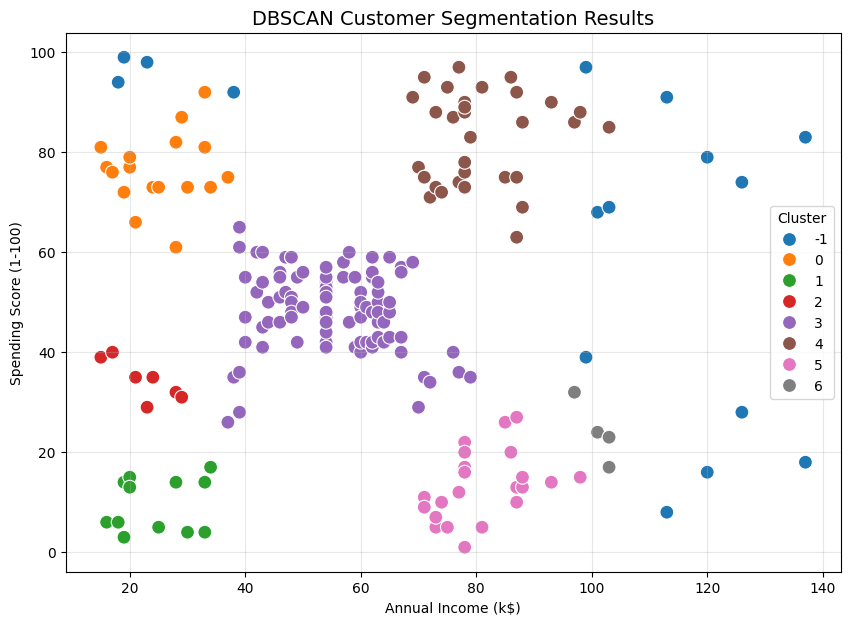

In [ ]:
# Task 6: Analyze Results and Cluster Statistics
# Append labels to original dataframe
df['Cluster'] = labels

# Calculate mean statistics per cluster
cluster_stats = df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)', 'Age']].mean().reset_index()
print("Cluster Statistics (Means):")
display(cluster_stats)

# Visualize the resulting clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    data=df,
    legend='full',
    s=100
)
plt.title('DBSCAN Customer Segmentation Results', fontsize=14)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
import pandas as pd
# Task 6: Summarize and interpret each customer segment group
print("### Customer Segment Characteristics ###")
for cluster_id in sorted(df['Cluster'].unique()):
    segment = df[df['Cluster'] == cluster_id]
    if cluster_id == -1:
        print(f"\nGroup {cluster_id} (Outliers/Noise): Size = {len(segment)}")
    else:
        print(f"\nGroup {cluster_id}: Size = {len(segment)}")
    print(f" - Age Range: {segment['Age'].min()} to {segment['Age'].max()} (Avg: {segment['Age'].mean():.1f})")
    print(f" - Income Range: {segment['Annual Income (k$)'].min()}k to {segment['Annual Income (k$)'].max()}k (Avg: {segment['Annual Income (k$)'].mean():.1f}k)")
    print(f" - Spending Score Range: {segment['Spending Score (1-100)'].min()} to {segment['Spending Score (1-100)'].max()} (Avg: {segment['Spending Score (1-100)'].mean():.1f})")

### Customer Segment Characteristics ###

Group -1 (Outliers/Noise): Size = 16
 - Age Range: 23 to 47 (Avg: 33.8)
 - Income Range: 18k to 137k (Avg: 93.2k)
 - Spending Score Range: 8 to 99 (Avg: 65.8)

Group 0: Size = 17
 - Age Range: 18 to 35 (Avg: 24.4)
 - Income Range: 15k to 37k (Avg: 25.2k)
 - Spending Score Range: 61 to 92 (Avg: 76.4)

Group 1: Size = 12
 - Age Range: 20 to 67 (Avg: 48.8)
 - Income Range: 16k to 34k (Avg: 24.6k)
 - Spending Score Range: 3 to 17 (Avg: 9.6)

Group 2: Size = 7
 - Age Range: 19 to 52 (Avg: 36.7)
 - Income Range: 15k to 29k (Avg: 22.4k)
 - Spending Score Range: 29 to 40 (Avg: 34.4)

Group 3: Size = 89
 - Age Range: 18 to 70 (Avg: 42.8)
 - Income Range: 37k to 79k (Avg: 55.0k)
 - Spending Score Range: 26 to 65 (Avg: 48.3)

Group 4: Size = 32
 - Age Range: 27 to 40 (Avg: 32.8)
 - Income Range: 69k to 103k (Avg: 80.5k)
 - Spending Score Range: 63 to 97 (Avg: 82.6)

Group 5: Size = 23
 - Age Range: 19 to 59 (Avg: 41.2)
 - Income Range: 71k to 98k (Avg: 81

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.